# DiffusionCB — 1-qubit CB harness

Trimmed clone of `CB/CB.ipynb` (1-qubit sim only). Project spec:
[`nonmarkovian_cb_diffusion_spec.md`](nonmarkovian_cb_diffusion_spec.md).

## Primer — one CB run

CB measures the per-Pauli fidelities **λ_P** that Standard RB averages away (SPAM-robust).

| symbol | what it is |
|---|---|
| **G** | gate / cycle **under test** (`I`, `H`) |
| **P** | **probe** Pauli — prep its +1 eigenstate, measure it (`X`,`Y`,`Z`) |
| **Rᵢ** | **random Pauli** twirl, fresh per cycle, uniform on `{I,X,Y,Z}` |

**Dressed cycle** = G wrapped by twirls `Rᵢ·G·Rᵢ₊₁` (randomized compiling → noise looks Pauli).

```
q0: ─[H]─[R0]─[G]─[R1]─[G]─[R2]─[H]─[M]      # P=X, m=2
     └prep┘ └─── dressed × m ───┘ └meas┘     # m copies of G, m+1 twirls
```

Each run → one overlap `f_{P,m,l} = Tr[C(P)·C̃(ρ)]` (= +1 if noiseless); average over `l=1..L` twirls → `F_m`.

`m` = # of G's. Run at short **m1** & long **m2**; SPAM cancels in the ratio:
`λ_P = (F_m2 / F_m1)^(1/(m2−m1))`.


In [1]:
# ── Cell 1 — Imports ──────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import itertools
from dataclasses import dataclass
from typing import Any
import time
import os

# Quantum info: Paulis, Cliffords, channel representations
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import (
    Pauli, PauliList, Clifford, Operator,
    SuperOp, PTM, DensityMatrix, random_pauli,
)

# Aer: simulator, noise channels, sampler primitive (hardware-portable path)
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel, QuantumError, ReadoutError,
    depolarizing_error, pauli_error, coherent_unitary_error,
)
from qiskit_aer.primitives import SamplerV2 as AerSampler
rng = np.random.default_rng(42)

In [2]:
# Cell 2 - Helpers
# make_cycle
def make_cycle(gate_name, n_qubits):
    # return the QC with the gate appended
    qc = QuantumCircuit(n_qubits)
    if gate_name == "I":
        order = 1
    elif gate_name == "s":
        order = 4
        for qbit in range(n_qubits):
            qc.s(qbit)
    elif gate_name == "cz":
        order = 2
        for qbit in range(0,  n_qubits-1, 2):
            qc.cz(qbit, qbit + 1)
    elif gate_name == "H":
        for qbit in range(n_qubits):
            qc.h(qbit)
        order = 2
    
    return qc, order

def make_noise(noise, n_qubits, label):
    kind = noise["kind"]
    full_error = None
    if kind == "correlated":
        full_error = pauli_error(list(noise["probs"].items()))
    else:
        if kind == "depolarizing":
            error = depolarizing_error(noise["p"], 1)
        elif kind == "pauli":
            error = pauli_error(list(noise["probs"].items()))
        full_error = error
        
        for _ in range(n_qubits -1):
            full_error = full_error.tensor(error)
    
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(full_error, label)
    return nm, full_error.to_quantumchannel()  

# create the pauli comnibations based on qubit size
# for 1 qubit = 4 paulis and 2 qubit =15 paulis use all of them as K
# for 3 qubits onwards trim the list to get a smaller K then len(paulis)

def make_paulis(n_qubits, rng, K=None):

    paulis = [''.join(p) for p in itertools.product("IXYZ", repeat = n_qubits)]
    paulis.remove("I"*n_qubits) # remove the identity
    if n_qubits>2 and K is not None and K<len(paulis):
        return [paulis[i] for i in rng.choice(len(paulis), size=K, replace=False)]
    else:
        return paulis # return as is do not trim for 1 and 2 qubits
    

In [3]:
# calculate expected lambdas for different noise models
'''noises = {
    "depolarizing": {"kind":"depolarizing", "p":0.05},
    "dephasing":    {"kind":"pauli", "probs":{"I":0.95, "Z":0.05}},
    "bit_flip":     {"kind":"pauli", "probs":{"I":0.95, "X":0.05}},
    "biased":       {"kind":"pauli", "probs":{"I":0.90, "X":0.03, "Y":0.02, "Z":0.05}},
}'''

@dataclass
class CBConfig:
     n_qubits: int
     shots: int
     m_list: tuple
     L: int
     K: int
     label: str
     rng: np.random.Generator
     factorization: bool = False
     transpile_fn: Any = None

# helpers for expected lambdas here

def to_probs(noise):
    if noise["kind"] == "depolarizing": 
        # see above depol doesnt have probs
        p = noise["p"]
        return {"I": 1-3*p/4, "X": p/4, "Y": p/4, "Z": p/4}
    return noise["probs"]

def expected_lambda(probs, P):
    P = Pauli(P)
    return sum(prob * (1 if P.commutes(Pauli(Q)) else -1) for Q, prob in probs.items())

# predicts what is lambda_P if noise were independent
def expected_lambda_orbit(probs, P, G_map):
    # ---- Step 1: FIND THE ORBIT (this loop is the orbit-finding) ----
    orbit, Q = [], Pauli(P)
    while True:
        label = Q.to_label().lstrip("+-i") # drop the sign
        orbit.append(label) # append to orbit
        Q = Q.evolve(G_map, frame="s") # sandiwch G with Q
        if Q.to_label().lstrip("+-i") == P: # string sign again and check if reached a circle, if yes stop. we found the orbit.
            break
    # ---- Step 2: BARE λ at each spot (per-qubit product) ----
    bare_lambdas = [np.prod([expected_lambda(probs, op) for op in label]) for label in orbit]

    # ---- Step 3: GEOMEAN (root = orbit size) ----
    return np.prod(bare_lambdas) ** (1 / len(orbit))    

In [4]:
# build the ideal cycle C(P) and the real_noisy_cycle C̃(ρ) for a given Pauli P, sequence length m and random sequence index l
'''
calcuate_ideal_circuit(P, qc):
Build the ideal dressed circuit (same twirls random_paulis + ideal G_map, no noise), then push the probe Pauli P through it classically:

output = Pauli(P).evolve(qc, frame='s')   # P → ±P  (Clifford circuit permutes/signs Paulis)
return 1 if output.phase == 0 else -1     # phase 0 → +1,  phase 2 → −1
Because everything ideal is Clifford, P maps to exactly ±P. That sign is the noiseless answer: measuring P on that circuit would give exactly +1 or −1, deterministically. It's computed on paper (no shots). '''

def calculate_ideal_circuit(P, qc):
    output = Pauli(P).evolve(qc, frame='s')
    assert output.phase in (0,2)
    return 1 if output.phase == 0 else -1
    

def prep_eigenstate(qc, P):
    for qbit, op in enumerate(P[::-1]): # we pass pauli as XZ but qiskit thinks Z is first qubit ie q0 so we reverse this by [::-1]
        if op == "X":
            qc.h(qbit)
        elif op == "Y":
            qc.h(qbit)
            qc.s(qbit)
    
def apply_dressed(qc, random_paulis, G):
    for i , random_pauli in enumerate(random_paulis):
        for qbit, op in enumerate(random_pauli[::-1]):
            if op == "X":
                qc.x(qbit)
            elif op == "Y":
                qc.y(qbit)
            elif op == "Z":
                qc.z(qbit)
        if i < len(random_paulis)-1:
            qc.append(G, range(qc.num_qubits))


def measure_P(qc, P):
    for qbit, op in enumerate(P[::-1]):
        if op == "X":
            qc.h(qbit)
        elif op == "Y":
            qc.sdg(qbit)
            qc.h(qbit)
    qc.measure(range(qc.num_qubits), range(qc.num_qubits))


def build_real_circuit(P, m, random_paulis, n_qubits, G_gate):
    qc = QuantumCircuit(n_qubits, n_qubits)
    prep_eigenstate(qc, P)
    apply_dressed(qc, random_paulis, G_gate)
    measure_P(qc, P)
    return qc

def run_once(P, m, cfg, G_map, G_gate, sampler):
    # this f_pml = Tr[C(P), C̃(ρ)] is the core of the protocol: one random sequence, one shot at the overlap
    random_paulis = ["".join(cfg.rng.choice(list("IXYZ"), cfg.n_qubits)) for _ in range(m+1)]

    run_qc = build_real_circuit(P, m, random_paulis, cfg.n_qubits, G_gate)

    if cfg.transpile_fn is not None:
        run_qc = cfg.transpile_fn(run_qc)

    ideal_qc = QuantumCircuit(cfg.n_qubits)
    apply_dressed(ideal_qc, random_paulis, G_map) # check this
    pauli_sign = calculate_ideal_circuit(P, ideal_qc)

    results = sampler.run([run_qc], shots=cfg.shots).result()
    counts = results[0].data.c.get_counts()
    return {"counts":counts, "pauli_sign":pauli_sign, "twirl_seq":random_paulis}

def get_expectation_value(counts, P, shots):
    P = P[::-1] # reverse to match qiskit's ordering
    total = 0
    for bitstring, c in counts.items():
        bitstring = bitstring[::-1] # reverse to match qiskit's ordering
        eigenvalue = 1
        for i in range(len(P)):
            if P[i] !="I" and bitstring[i] =='1':
                eigenvalue *= -1
        total += eigenvalue * c
    return total / shots

'''P has only ±1 eigenvalues. The loop's whole job is: for each measured bitstring, decide whether it's the +1 outcome or the −1 outcome — then average them. ⟨P⟩ is the average of those ±1's, so a number in [−1, +1].

1. For 1 qubit it's trivial (P="Z"): bit "0" → +1, bit "1" → −1. With counts={"0":95,"1":5}:

<Z> = (95·(+1) + 5·(−1)) / 100 = 0.9

That's all. The loop for n=1 literally does (-1)^0 = +1 for "0" and (-1)^1 = −1 for "1".

2. For multiple qubits, a single bitstring's eigenvalue isn't one bit — it's the product of each qubit's ±1. After measure_P rotates P→Z…Z, each qubit gives +1 (bit 0) or −1 (bit 1), and P's eigenvalue is their product:

eigenvalue = (+1 or −1) × (+1 or −1) × ...   over P's support
           = (−1)^(number of 1-bits on the support)
    
'''

def run_cb(paulis_K, cfg, G_map, G_gate, sampler):
    record_runs = {}
    t0 = time.time()
    print("==================================================================")
    print(f"Running for {len(paulis_K)} Paulis: {paulis_K}")
    for i, P in enumerate(paulis_K):
        record_runs[P] = {} # dict within dict to store results for each P
        for m in (cfg.m_list):
            record_runs[P][m] = [run_once(P, m, cfg, G_map, G_gate, sampler) for _ in range(cfg.L)]
        elapsed = time.time()-t0
        print(f"[{i+1:>2}/{len(paulis_K)}] P={P:<3}  m={list(record_runs[P])} × {cfg.L} seqs [L]  (elapsed {elapsed:.1f}s)", flush=True)

    return record_runs

def print_lambdas(name, measured, expected=None):
    print(f"\n  {name}")
    if expected is None:
        print(f"  {'P':<5}{'measured':>10}")
        for P in measured:
            print(f"  {P:<5}{measured[P]:>10.4f}")
        print(f"  {'F_RC':<5}{np.mean(list(measured.values())):>10.4f}")
    else:    
        print(f"  {'P':<5}{'expected':>10}{'measured':>10}{'Δ':>9}")
        for P in expected:
            print(f"  {P:<5}{expected[P]:>10.4f}{measured[P]:>10.4f}{measured[P]-expected[P]:>+9.4f}")
        e, m = np.mean(list(expected.values())), np.mean(list(measured.values()))
        print("--------------------------------------------")
        print(f"  {'F_RC':<5}{e:>10.4f}{m:>10.4f}{m-e:>+9.4f}")

def lambda_from_records(record_runs, cfg):
    lambdas = {}
    for P, m_dict in record_runs.items():
        F = {}
        for m, runs in m_dict.items():
            #f_{P,m,l} = Tr[ (ε_l · P) · C̃(ρ) ] = ε_l · Tr[ P · C̃(ρ) ]
            #f_{P,m,l} = ε_l · ⟨P⟩

            f_pmls = [run["pauli_sign"] * get_expectation_value(run["counts"], P, cfg.shots) for run in runs]
            F[m] = np.mean(f_pmls)
        m1 = cfg.m_list[0]
        m2 = cfg.m_list[-1]
        lambdas[P] = (F[m2]/F[m1]) ** (1/(m2-m1))
    return lambdas
   

In [5]:
# the run experiment 

def run_experiment(cfg, cycle_gates, noises):
    paulis = make_paulis(cfg.n_qubits, cfg.rng, cfg.K)
    all_records = {}
    for cycle_gate in cycle_gates:
        G_map, order = make_cycle(cycle_gate, cfg.n_qubits)
        G_gate = UnitaryGate(Operator(G_map).data, label=cfg.label)
        print("==================================================================")
        print(f"Cycle {cycle_gate} (order {order}), {cfg.n_qubits} qubit — expected vs measured λ_P")
        # run the cycle benckhmarking 
        for name, noise in noises.items():
            # expected results
            if (noise["kind"] in ("depolarizing", "pauli")):
                probs = to_probs(noise)
                expected_lambdas = {P: expected_lambda_orbit(probs, P, G_map) for P in paulis}
            elif noise["kind"] == "correlated":
                probs = noise["marginal_probs"]
                expected_lambdas = {P: expected_lambda_orbit(probs, P, G_map) for P in paulis}
                
            else:
                expected_lambdas = None

            # now the real circuit run with noise
            nm, channel = make_noise(noise, cfg.n_qubits, cfg.label)
            sampler = AerSampler(options = {"backend_options":{"noise_model": nm}})
            record_runs = run_cb(paulis, cfg, G_map, G_gate, sampler)
            all_records[(cycle_gate, name)] = record_runs
            measured_lambdas = lambda_from_records(record_runs, cfg)
            print_lambdas(name, measured_lambdas, expected_lambdas)
    return all_records    


In [6]:
# (terminology + one-circuit primer: see the top markdown cell)

# --- Noise on G. CB measures lambda_P = survival of P-component:  Lambda(P) = lambda_P * P.
#"Channels preserve I" is the statement λ_I = 1 — and that's automatic, regardless of p_I: λ_I = p_I + p_X + p_Y + p_Z = (1−q) + q = 1 
#
# lambda_P = P(errors COMMUTING with P) - P(errors ANTICOMMUTING with P)
# commute: X~I,X | Y~I,Y | Z~I,Z ; each anticommutes with the other two)
# lambda_I = 1 <- always; I never decays, so not measured
#       lambda_X = (pI+pX) - (pY+pZ)
#       lambda_Y = (pI+pY) - (pX+pZ)
#       lambda_Z = (pI+pZ) - (pX+pY)
# 
# expected CB output (verify against this): order is (λ_X, λ_Y, λ_Z)
# interestingly e.g Z damages X and Y and Z is left alone e.g. dephasing
#   depolarizing p {"kind":"depolarizing","p":p} -> (1-p, 1-p, 1-p)
#   dephasing-q {"kind":"pauli","probs":{"I":1-q,"Z":q}} -> (1-2q,  1-2q,  1)
#   bit-flip-q {"kind":"pauli","probs":{"I":1-q,"X":q}} -> (1,1-2q,  1-2q)
#   biased {"I":.90,"X":.03,"Y":.02,"Z":.05} -> (0.86,  0.84,  0.90)
CYCLE_LABEL = "CB_Cycle"
noises = {
    "depolarizing": {"kind":"depolarizing", "p":0.05},
    "dephasing":    {"kind":"pauli", "probs":{"I":0.95, "Z":0.05}},
    "bit_flip":     {"kind":"pauli", "probs":{"I":0.95, "X":0.05}},
    "biased":       {"kind":"pauli", "probs":{"I":0.90, "X":0.03, "Y":0.02, "Z":0.05}},
}

cfg = CBConfig(n_qubits=1, shots=1024, m_list=(2, 4, 6, 8, 12, 16), L=30, K=30, rng=rng, label=CYCLE_LABEL)
all_records = run_experiment(cfg, ["I", "H"], noises)

Cycle I (order 1), 1 qubit — expected vs measured λ_P
Running for 3 Paulis: ['X', 'Y', 'Z']
[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.4s)
[ 2/3] P=Y    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.7s)
[ 3/3] P=Z    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 1.1s)

  depolarizing
  P      expected  measured        Δ
  X        0.9500    0.9501  +0.0001
  Y        0.9500    0.9496  -0.0004
  Z        0.9500    0.9495  -0.0005
--------------------------------------------
  F_RC     0.9500    0.9498  -0.0002
Running for 3 Paulis: ['X', 'Y', 'Z']
[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.3s)
[ 2/3] P=Y    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.7s)
[ 3/3] P=Z    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 1.0s)

  dephasing
  P      expected  measured        Δ
  X        0.9000    0.8978  -0.0022
  Y        0.9000    0.9030  +0.0030
  Z        1.0000    1.0000  +0.0000
--------------------------------------------
  F_RC     0.933

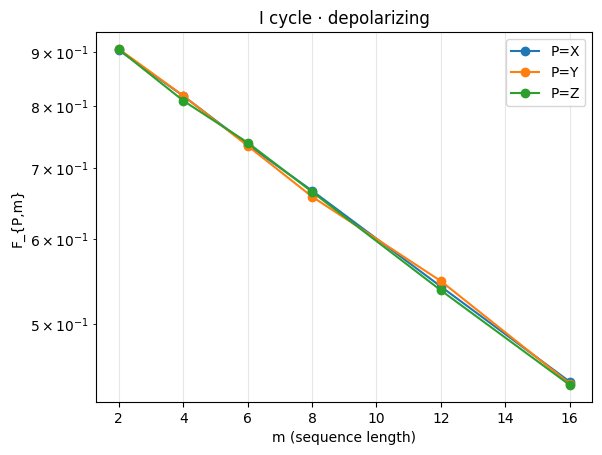

In [8]:
def plot_decay(record_runs, cfg, title=""):
    for P, m_dict in record_runs.items():
        ms = sorted(m_dict)
        F  = [np.mean([r["pauli_sign"] * get_expectation_value(r["counts"], P, cfg.shots)
                       for r in m_dict[m]]) for m in ms]
        plt.plot(ms, F, "o-", label=f"P={P}")
    plt.xlabel("m (sequence length)")
    plt.ylabel("F_{P,m}")
    plt.yscale("log")
    plt.title(title)
    plt.legend(); plt.grid(True, alpha=0.3); plt.show()

plot_decay(all_records[("I", "depolarizing")], cfg, title="I cycle · depolarizing")
